# Diabetes Risk Classification: Traditional ML vs Deep Learning

Machine Learning summative project, African Leadership University.

This notebook grows step by step. **Step 2 (this part): Exploratory Data Analysis (EDA).**
Later steps (preprocessing, models, experiments, error analysis) will be added below.

**Goal of the project:** predict whether a person has diabetes from health-survey answers, then compare traditional machine learning (scikit-learn) with deep learning (TensorFlow/Keras).

## 1. Setup
Import the libraries, fix the random seed (so results can be repeated) and find the dataset file.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

# The notebook lives in notebooks/, the data lives in dataset/ one folder up.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_FILE = ROOT / "dataset" / "diabetes_binary_health_indicators_BRFSS2015.csv"
OTHER_FILE = ROOT / "dataset" / "diabetes_012_health_indicators_BRFSS2015.csv"   # 3-class version, only used to check the target
IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)

# Two colours that are easy to tell apart (also for colour-blind readers)
BLUE, ORANGE = "#0072B2", "#D55E00"

def save_and_show(name):
    # Save the current figure in images/ (used later in the report) and display it.
    plt.savefig(IMAGES / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()

print("Looking for data in:", DATA_FILE)
print("File found:", DATA_FILE.exists())

Looking for data in: /Users/MAC/Documents/projects/ALU/summative_introduction_to_machine_learning/dataset/diabetes_binary_health_indicators_BRFSS2015.csv
File found: True


## 2. Load the data and take a first look

In [2]:
df = pd.read_csv(DATA_FILE)
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print("The assignment needs at least 20,000 raw rows ->", "OK" if df.shape[0] >= 20000 else "NOT ENOUGH")
df.head()

Rows: 253680 | Columns: 22
The assignment needs at least 20,000 raw rows -> OK


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [3]:
# Data types: everything is stored as float even though most columns are 0/1 answers
df.dtypes

Diabetes_binary         float64
HighBP                  float64
HighChol                float64
CholCheck               float64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity            float64
Fruits                  float64
Veggies                 float64
HvyAlcoholConsump       float64
AnyHealthcare           float64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                     float64
Age                     float64
Education               float64
Income                  float64
dtype: object

### What the columns mean
All columns come from the CDC BRFSS 2015 telephone survey (self-reported answers). Short descriptions, based on the dataset documentation and the BRFSS codebook (I will double-check the coding of the last few against the codebook before the report):

| Column | Meaning |
|---|---|
| **Diabetes_binary** | **Target.** 0 = no diabetes, 1 = diabetes |
| HighBP, HighChol | told by a doctor that blood pressure / cholesterol is high (0/1) |
| CholCheck | cholesterol checked in the last 5 years (0/1) |
| BMI | body mass index (number) |
| Smoker | smoked at least 100 cigarettes in life (0/1) |
| Stroke, HeartDiseaseorAttack | ever told they had a stroke / heart disease or heart attack (0/1) |
| PhysActivity | physical activity in the last 30 days, not counting the job (0/1) |
| Fruits, Veggies | eats fruit / vegetables at least once a day (0/1) |
| HvyAlcoholConsump | heavy drinker (0/1) |
| AnyHealthcare, NoDocbcCost | has health coverage / could not see a doctor because of cost (0/1) |
| GenHlth | general health, 1 = excellent ... 5 = poor |
| MentHlth, PhysHlth | days of poor mental / physical health in the last 30 days (0 to 30) |
| DiffWalk | serious difficulty walking or climbing stairs (0/1) |
| Sex | 0 = female, 1 = male |
| Age | age group, 1 = 18-24 ... 13 = 80 or older (5-year groups) |
| Education | 1 (never attended school) to 6 (college graduate) |
| Income | 1 (less than $10,000) to 8 ($75,000 or more) |

## 3. Data quality checks
Missing values, duplicate rows and impossible values.

In [4]:
print("Missing values in total:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum(), f"({df.duplicated().mean():.1%} of the data)")

# Which columns only contain 0 and 1?
binary_cols = [c for c in df.columns if set(df[c].unique()) <= {0.0, 1.0}]
other_cols = [c for c in df.columns if c not in binary_cols]
print("\nBinary (0/1) columns:", len(binary_cols))
print("Other columns:", other_cols)

Missing values in total: 0
Duplicate rows: 24206 (9.5% of the data)

Binary (0/1) columns: 15
Other columns: ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']


In [5]:
# Summary statistics for the non-binary columns, to spot impossible values
df[other_cols].describe().round(2)

,BMI,GenHlth,MentHlth,PhysHlth,Age,Education,Income
count,253680.00,253680.00,253680.00,253680.00,253680.00,253680.00,253680.00
mean,28.38,2.51,3.18,4.24,8.03,5.05,6.05
std,6.61,1.07,7.41,8.72,3.05,0.99,2.07
min,12.00,1.00,0.00,0.00,1.00,1.00,1.00
25%,24.00,2.00,0.00,0.00,6.00,4.00,5.00
50%,27.00,2.00,0.00,0.00,8.00,5.00,7.00
75%,31.00,3.00,2.00,3.00,10.00,6.00,8.00
max,98.00,5.00,30.00,30.00,13.00,6.00,8.00


**Note on duplicates.** The survey has only 22 mostly yes/no answers, so two different people can easily give exactly the same answers. These duplicates are therefore not necessarily errors. They matter later, because an identical row could land in both the training set and the test set. I will decide how to handle them in the preprocessing step.

## 4. The target variable

In [6]:
counts = df["Diabetes_binary"].value_counts().sort_index()
share = df["Diabetes_binary"].value_counts(normalize=True).sort_index()
summary = pd.DataFrame({"people": counts, "share": share.round(3)})
summary.index = ["0 = no diabetes", "1 = diabetes"]
print(summary)
print("\nA model that always says 'no diabetes' would already be right", f"{share[0]:.1%}", "of the time.")

                 people  share
0 = no diabetes  218334  0.861
1 = diabetes      35346  0.139

A model that always says 'no diabetes' would already be right 86.1% of the time.


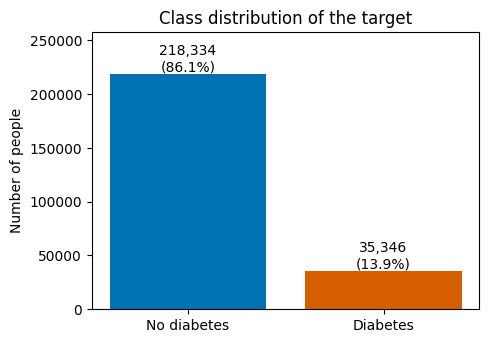

In [7]:
fig, ax = plt.subplots(figsize=(5, 3.6))
ax.bar(["No diabetes", "Diabetes"], counts.values, color=[BLUE, ORANGE])
for i, n in enumerate(counts.values):
    ax.text(i, n, f"{n:,}\n({share.values[i]:.1%})", ha="center", va="bottom")
ax.set_ylabel("Number of people")
ax.set_title("Class distribution of the target")
ax.set_ylim(0, counts.max() * 1.18)
save_and_show("eda01_class_distribution")

In [8]:
# What does 'diabetes = 1' mean here? Compare with the 3-class file (0 = none, 1 = prediabetes, 2 = diabetes).
three = pd.read_csv(OTHER_FILE)
print("Same number of rows in both files:", len(three) == len(df))
print("3-class counts:", three["Diabetes_012"].value_counts().sort_index().to_dict())
print("Binary target == (3-class target is 2) for every row:", bool((df["Diabetes_binary"].values == (three["Diabetes_012"].values == 2)).all()))

Same number of rows in both files: True
3-class counts: {0.0: 213703, 1.0: 4631, 2.0: 35346}
Binary target == (3-class target is 2) for every row: True


The check above shows what the binary label contains: it is 1 only for the people marked as diabetes in the 3-class file, so **prediabetes people are counted as "no diabetes"** in this binary file. The UCI page describes the label as "prediabetes or diabetes", which does not match the data. I will mention this in the limitations of the report.

**Imbalance:** about 14 out of every 100 people have diabetes. Accuracy will look high even for a useless model, so I will also use precision, recall, F1 and ROC-AUC, and I will try class weights.

## 5. Distributions of the numeric features

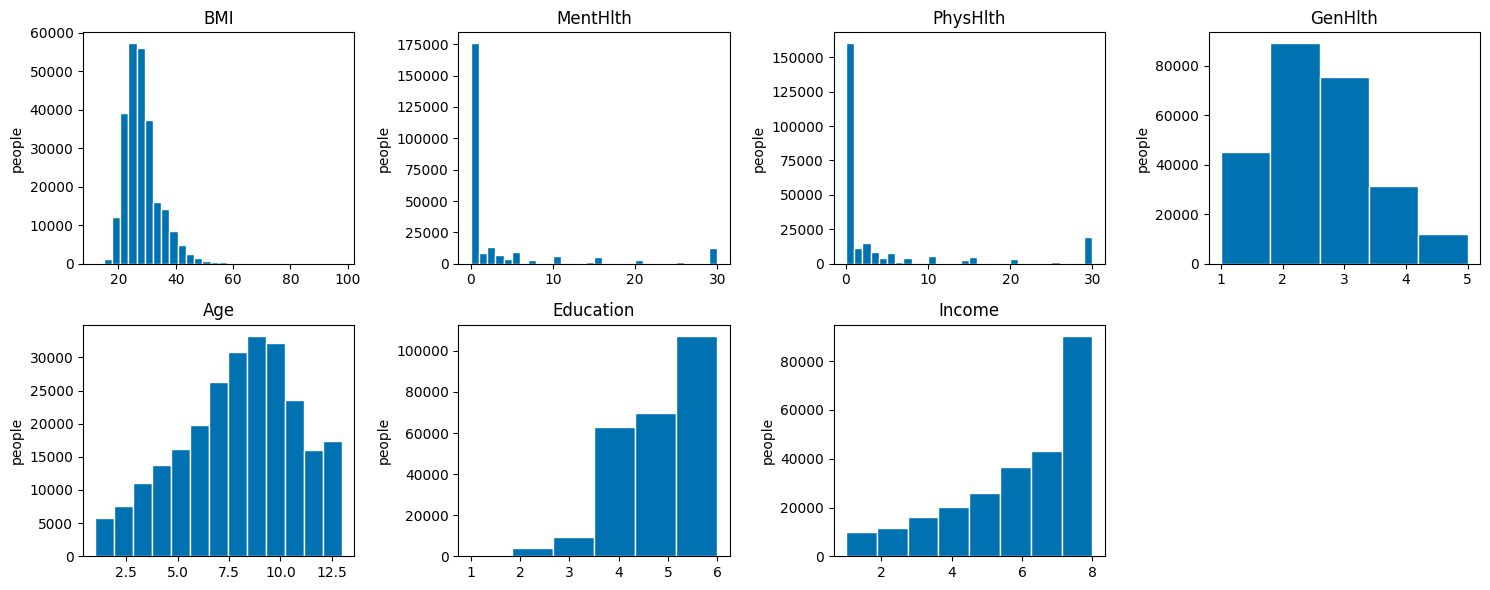

In [9]:
numeric_features = ["BMI", "MentHlth", "PhysHlth", "GenHlth", "Age", "Education", "Income"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, col in zip(axes.ravel(), numeric_features):
    ax.hist(df[col], bins=min(30, df[col].nunique()), color=BLUE, edgecolor="white")
    ax.set_title(col)
    ax.set_ylabel("people")
axes.ravel()[-1].axis("off")      # 7 plots on a 2x4 grid -> hide the empty one
plt.tight_layout()
save_and_show("eda02_numeric_distributions")

### Outliers in BMI
BMI is the only truly continuous measurement, so it is the main place where outliers can appear. I use the usual IQR rule (anything beyond 1.5 x IQR from the quartiles).

In [10]:
q1, q3 = df["BMI"].quantile([0.25, 0.75])
iqr = q3 - q1
low_limit, high_limit = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_outlier = (df["BMI"] < low_limit) | (df["BMI"] > high_limit)
print(f"BMI range: {df['BMI'].min():.0f} to {df['BMI'].max():.0f} | median {df['BMI'].median():.0f}")
print(f"IQR rule limits: {low_limit:.1f} to {high_limit:.1f}")
print(f"BMI outliers: {is_outlier.sum():,} rows ({is_outlier.mean():.1%})")
print("Diabetes rate among BMI outliers:", f"{df.loc[is_outlier, 'Diabetes_binary'].mean():.1%}", "| among the rest:", f"{df.loc[~is_outlier, 'Diabetes_binary'].mean():.1%}")
print("BMI above 60:", (df["BMI"] > 60).sum(), "| BMI below 15:", (df["BMI"] < 15).sum())

BMI range: 12 to 98 | median 27
IQR rule limits: 13.5 to 41.5
BMI outliers: 9,847 rows (3.9%)
Diabetes rate among BMI outliers: 34.2% | among the rest: 13.1%
BMI above 60: 805 | BMI below 15: 68


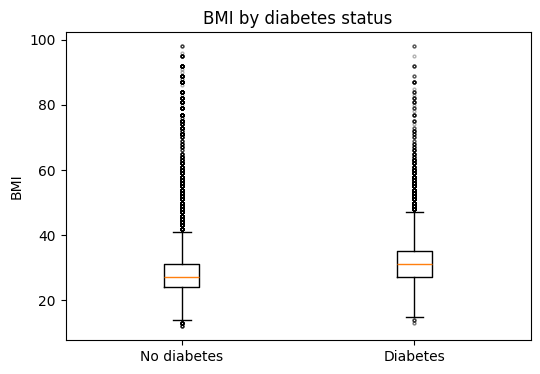

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([df.loc[df["Diabetes_binary"] == 0, "BMI"], df.loc[df["Diabetes_binary"] == 1, "BMI"]],
           tick_labels=["No diabetes", "Diabetes"], flierprops={"markersize": 2, "alpha": 0.3})
ax.set_ylabel("BMI")
ax.set_title("BMI by diabetes status")
save_and_show("eda03_bmi_boxplot")

Many BMI values above the IQR limit are real (very high BMI exists), so they are not automatically errors. I will decide in the preprocessing step whether to cap them rather than delete them.

## 6. Relationship between each feature and diabetes
These plots show **associations**, not causes. For example, people with high blood pressure having more diabetes does not prove that high blood pressure causes diabetes.

In [12]:
# Diabetes rate for people answering 0 vs 1 on each yes/no question
rows = []
for col in binary_cols:
    if col == "Diabetes_binary":
        continue
    rate_no = df.loc[df[col] == 0, "Diabetes_binary"].mean()
    rate_yes = df.loc[df[col] == 1, "Diabetes_binary"].mean()
    rows.append({"feature": col, "rate_if_0": rate_no, "rate_if_1": rate_yes, "difference": rate_yes - rate_no})
rate_table = pd.DataFrame(rows).sort_values("difference")
rate_table.round(3)

,feature,rate_if_0,rate_if_1,difference
6,PhysActivity,0.211,0.116,-0.095
9,HvyAlcoholConsump,0.144,0.058,-0.086
8,Veggies,0.180,0.130,-0.050
7,Fruits,0.158,0.129,-0.029
13,Sex,0.130,0.152,0.022
10,AnyHealthcare,0.115,0.141,0.026
11,NoDocbcCost,0.136,0.175,0.039
3,Smoker,0.121,0.163,0.042
2,CholCheck,0.025,0.144,0.118
1,HighChol,0.080,0.220,0.140


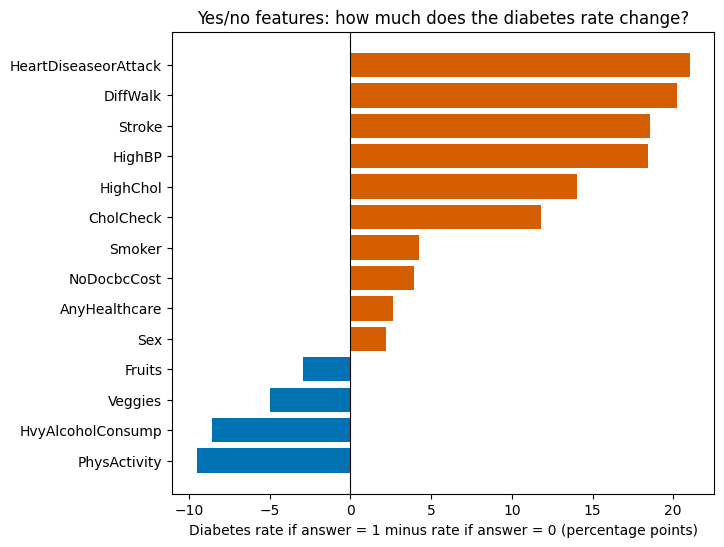

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))
colors = [ORANGE if d > 0 else BLUE for d in rate_table["difference"]]
ax.barh(rate_table["feature"], rate_table["difference"] * 100, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Diabetes rate if answer = 1 minus rate if answer = 0 (percentage points)")
ax.set_title("Yes/no features: how much does the diabetes rate change?")
save_and_show("eda04_binary_feature_effects")

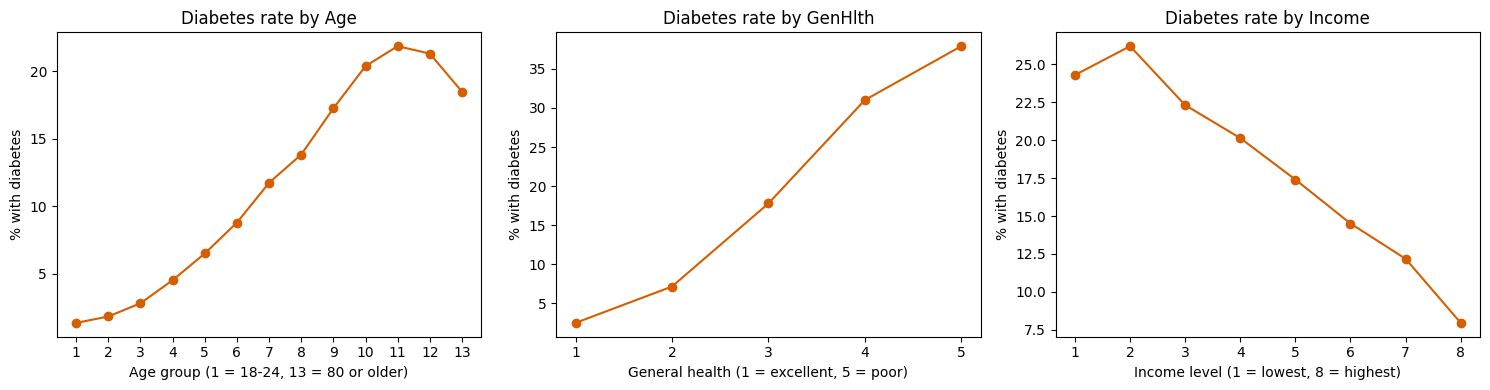

             people  diabetes_rate
BMI                               
underweight    3127          0.054
normal        68953          0.057
overweight    93749          0.114
obese         87851          0.234


In [14]:
# Diabetes rate by age group, general health and income (ordered features)
# One x-axis label per feature, because the meaning of "1" is different for each one
axis_labels = {"Age": "Age group (1 = 18-24, 13 = 80 or older)",
               "GenHlth": "General health (1 = excellent, 5 = poor)",
               "Income": "Income level (1 = lowest, 8 = highest)"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Age", "GenHlth", "Income"]):
    rate = df.groupby(col)["Diabetes_binary"].mean() * 100
    ax.plot(rate.index, rate.values, marker="o", color=ORANGE)
    ax.set_xticks(rate.index.astype(int))          # whole numbers only, these are categories
    ax.set_xlabel(axis_labels[col])
    ax.set_ylabel("% with diabetes")
    ax.set_title(f"Diabetes rate by {col}")
plt.tight_layout()
save_and_show("eda05_rate_by_ordered_features")

# BMI categories from the WHO cut-offs
bmi_groups = pd.cut(df["BMI"], [0, 18.5, 25, 30, 100], labels=["underweight", "normal", "overweight", "obese"], right=False)
print(df.groupby(bmi_groups, observed=True)["Diabetes_binary"].agg(people="size", diabetes_rate="mean").round(3))

## 7. Correlations
Pearson correlation between every feature and the target. Because most columns are 0/1 or ordered codes, this is only a rough guide. It also only catches straight-line relationships.

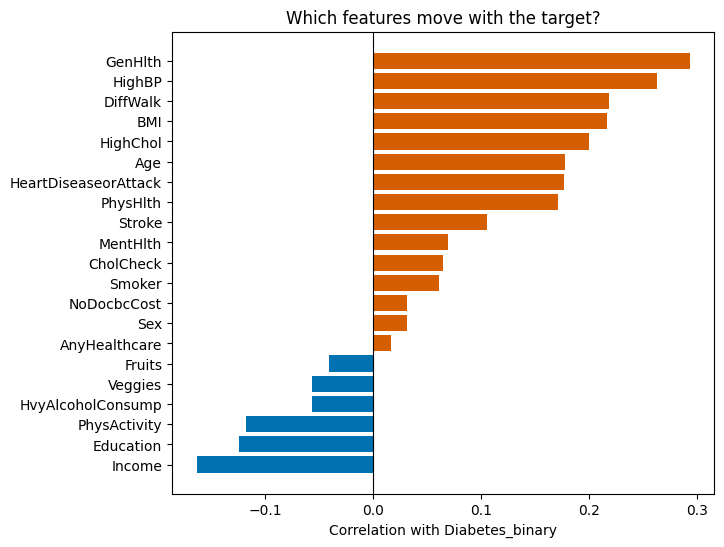

Income                 -0.164
Education              -0.124
PhysActivity           -0.118
HvyAlcoholConsump      -0.057
Veggies                -0.057
Fruits                 -0.041
AnyHealthcare           0.016
Sex                     0.031
NoDocbcCost             0.031
Smoker                  0.061
CholCheck               0.065
MentHlth                0.069
Stroke                  0.106
PhysHlth                0.171
HeartDiseaseorAttack    0.177
Age                     0.177
HighChol                0.200
BMI                     0.217
DiffWalk                0.218
HighBP                  0.263
GenHlth                 0.294


In [15]:
corr_with_target = df.corr()["Diabetes_binary"].drop("Diabetes_binary").sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(corr_with_target.index, corr_with_target.values, color=[ORANGE if v > 0 else BLUE for v in corr_with_target.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Correlation with Diabetes_binary")
ax.set_title("Which features move with the target?")
save_and_show("eda06_target_correlation")
print(corr_with_target.round(3).to_string())

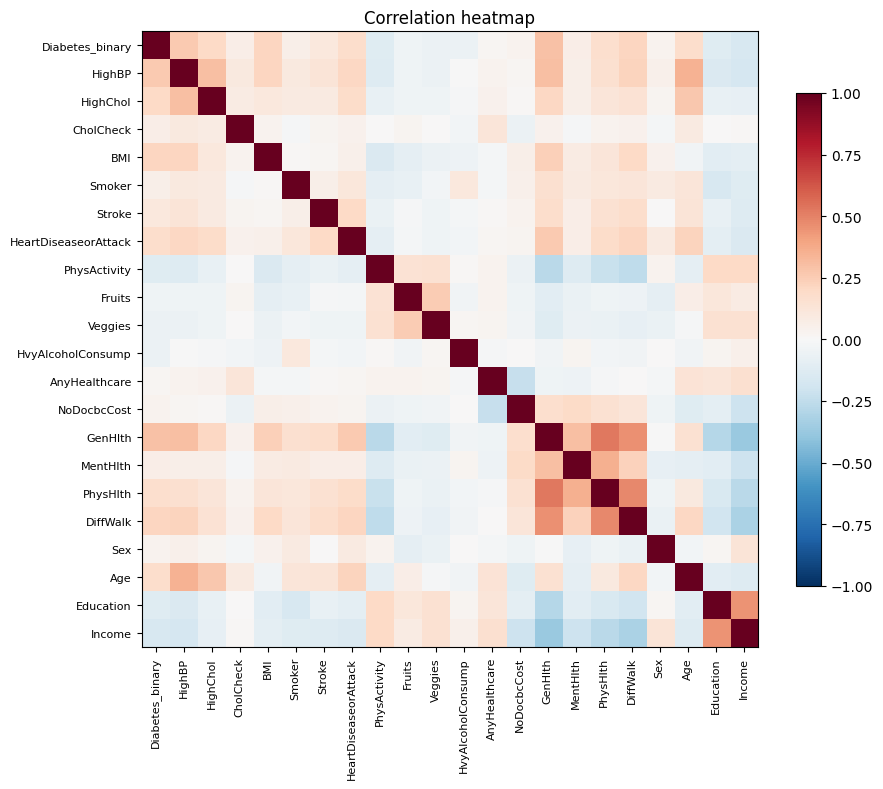

Strongest feature-to-feature correlations:
GenHlth    PhysHlth    0.524
PhysHlth   DiffWalk    0.478
GenHlth    DiffWalk    0.457
Education  Income      0.449
GenHlth    Income     -0.370


In [16]:
# Correlation heatmap of all columns (looking for features that carry similar information)
corr = df.corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation heatmap")
save_and_show("eda07_correlation_heatmap")

# Pairs of features that are strongly related to each other (not counting the target)
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
pairs = pairs.drop(labels=[i for i in pairs.index if "Diabetes_binary" in i])
print("Strongest feature-to-feature correlations:")
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(5).round(3).to_string())

## 8. EDA summary

**Facts from the output above** (checked against the cells):
- The raw file has 253,680 rows and 22 columns, so it meets the 20,000-row requirement. There are no missing values.
- Only about 14% of people have diabetes, so the classes are strongly imbalanced.
- The binary target does not include prediabetes (those people are labelled 0).
- There are 24,206 exact duplicate rows. With only yes/no style answers this is expected, but it needs a decision before splitting the data.
- BMI is the only continuous feature and it has a long right tail.

**My interpretation (to write in my own words before moving on):**
1. Which features seem most related to diabetes, and does that match what I know about the disease?
2. What problems will the imbalance cause for the models, and what will I do about it?
3. What preprocessing decisions follow from this EDA (duplicates, BMI outliers, scaling, feature ideas)?